In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import scipy.stats as st
import os
import datetime
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
sns.set_context('paper')
import gseapy
# gseapy.get_library_name()
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append('..')  # div.py lives in the repository root
from div import *
from matplotlib_venn import venn2
sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()

%load_ext autoreload
%autoreload 2

2026-10-13  11:14:05


In [ ]:
nnow()
input_path = '../GTEx_upstream/'
tpm = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
tpm = np.log2(tpm + 1)
tpm_untn = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
div = pd.read_csv(input_path  + 'div1.csv.gz', index_col=0)
metadata = pd.read_csv(input_path  + 'metadata.csv.gz', index_col=0)
gene_info = pd.read_csv(input_path  + 'gene_annotation.csv.gz', index_col=0)

pth = os.getcwd() + '/'
tables_main_path = pth + 'tables_main/'


if not os.path.isdir(tables_main_path):
    os.mkdir(tables_main_path)
if not os.path.isdir(pth + 'figs_limma_equivalence/'):
    os.mkdir(pth + 'figs_limma_equivalence/')
if not os.path.isdir(pth + 'tables_limma_equivalence/'):
    os.mkdir(pth + 'tables_limma_equivalence/')
    
source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'


tissue_pairwise_overview_path = '../GTEx_pre_downstream/fig2_tissue_pairs/'
smtsd_overview_df = pd.read_csv(tissue_pairwise_overview_path + 'SMTSD_limma/overview_cluster_results.csv').drop(columns='Unnamed: 0')
smts_overview_df = pd.read_csv(tissue_pairwise_overview_path + 'SMTS_limma/overview_cluster_results.csv').drop(columns='Unnamed: 0')
brain_overview_df = smtsd_overview_df.loc[(smtsd_overview_df.t1.str.contains('Brain') & (smtsd_overview_df.t2.str.contains('Brain')))]

2026-10-13  11:25:10


In [ ]:
def pval_to_asterisks(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.01:
        return '**'
    elif p <= 0.05:
        return '*'
    else:
        return ''
    
def format_small_number(v):
    if 'e' in str(v):
        val, x, powerof = str(v).replace("e", " x 10^").split(' ')
        formatted = ''.join([f"{float(val):.2f}", x, powerof])
    else:
        formatted = f"{v:.2f}"
    return formatted

def annotpval(pv):
    if float(f'{pv:.2e}') == 0.00e+00:
        return 'p<10^-323'
    else:
        return f'p={pv:.2e}'.replace("e", "x10^")
    
def make_gene_list(basedon, idx_tissuepair, what_to_return):

    input_path = tissue_pairwise_overview_path + f'{basedon}_limma/'
    filenames_dict = {}
    filenames_dict['div'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_tissuepair) + '.')) & (f.endswith('.div.limma_DE_equiv.csv.gz'))][0]
    filenames_dict['tpm'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_tissuepair) + '.')) & (f.endswith('.tpm.limma_DE_equiv.csv.gz'))][0]

    div_limma = pd.read_csv(input_path + filenames_dict['div'], compression='gzip', index_col='gene')
    tpm_limma = pd.read_csv(input_path + filenames_dict['tpm'], compression='gzip', index_col='gene')
    
    if what_to_return == 'div':
        return div_limma    
    if what_to_return == 'tpm':
        return tpm_limma
    
    genes_lists = {}
    genes_lists[basedon] = filenames_dict['div'].split('.')[1:3]
    genes_lists['all'] = gene_info.index.to_list()
    genes_lists['tpm_eq'] = tpm_limma.loc[(tpm_limma.AveExpr > 0) & (tpm_limma['classification'] == 'equivalent')].index.to_list()
    genes_lists['div_eq'] = div_limma.loc[(div_limma.AveExpr > 0) & (div_limma['classification'] == 'equivalent')].index.to_list()
    
    if what_to_return == 'genes':
        return genes_lists



def make_pca(metric, gene_list, sample_list):
    n_components = 2
    pca = PCA(n_components=n_components)
    scaler = StandardScaler()
    basedon = [k  for k in genes_lists.keys() if 'SMTS' in k][0]
    scaled_features = scaler.fit_transform(metric.loc[metric.index.isin(gene_list), sample_list  ].T)
    pca_result = pd.DataFrame(pca.fit_transform(scaled_features), index = sample_list).join(metadata[basedon])
    var1 = pca.explained_variance_ratio_[0]
    var2 = pca.explained_variance_ratio_[1]

    label_dict = {l: i for i,l in enumerate(pca_result[basedon].unique())}
    silhouette_sc = silhouette_score(pca_result[[0,1]].values, pca_result[basedon].map(label_dict))


    # rank genes that drive separation
    loadings = pd.DataFrame(
        pca.components_.T, 
        index=gene_list, 
        columns=[f'PC{i+1}' for i in range(pca.n_components_)]).join(gene_info)


    return pca_result, var1, var2, silhouette_sc, loadings


def make_silhuette_pvtbl(metric, baseon):
    summary_lowvar_df = pd.read_csv(tissue_pairwise_overview_path + f'{baseon}_limma/overview_cluster_results.csv').drop(columns='Unnamed: 0')
    # summary_lowvar_df[['t1', 't2']] = list(combinations(metadata[baseon].unique(), 2))
    df_copy1 = summary_lowvar_df[['t1','t2',metric]]
    return pd.pivot_table(pd.concat([df_copy1,df_copy1.rename(columns={'t1':'t2', 't2':'t1'})]), columns = 't1', index = 't2', values = metric)

def make_combined_trui_tril(metric_, baseon_):

    sil_tpm = make_silhuette_pvtbl(metric= metric_ + 'tpm', baseon = baseon_)
    sil_div = make_silhuette_pvtbl(metric= metric_ + 'div', baseon = baseon_)

    sorted_index = sorted(sil_div.index)
    sortd_columns = sorted(sil_div.columns)

    upper_triangle = pd.DataFrame(np.triu(sil_tpm.loc[sortd_columns,sortd_columns], k=0), index=sorted_index, columns=sortd_columns) 
    lower_triangle = pd.DataFrame(np.tril(sil_div.loc[sortd_columns,sortd_columns], k=-1), index=sorted_index, columns=sortd_columns) 

    return upper_triangle + lower_triangle


def plot_pairwise_PCA(savefig = False, filename=''):
    
    h = pca_result.drop(columns=[0,1]).columns[0]#SMTS or SMTSD
    
    t1, t2 = genes_lists[h]
    cplt = {t1: 'Teal', t2: 'Coral'}
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(0.75,0.75))
    sns.scatterplot(data= pca_result, x=0, y=1, alpha=0.75, s=3, edgecolor='None',hue= h, 
                    palette=cplt, ax = ax)
    ax.set(xlabel = 'PC 1: ' + str(round(var1*100,2)), 
        ylabel='PC 2: ' + str(round(var2*100,2)))
    ax.set_title(f'SC={silhouette_sc:.2}' + f'\nn={len(loadings)}', loc='left')
    # ax.tick_params(left=False, bottom=False) ## other options are right and top
    ax.tick_params(length=2.5) ## other options are right and top
    ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
    ax.set_xlabel('PC 1: ' + str(round(var1*100,2)),labelpad=0)
    ax.set_ylabel('PC 2: ' + str(round(var2*100,2)),labelpad=0)

    legend_handles = [
        Line2D([], [], marker='o', linestyle='None', markerfacecolor=cplt[t1],markeredgewidth=0.25,
            markeredgecolor='none', markersize=3, label=t1),
        Line2D([], [], marker='o', linestyle='None', markerfacecolor=cplt[t2],markeredgewidth=0.25,
            markeredgecolor='none', markersize=3, label=t2),
    ]
    ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
    sns.despine()
    
    if savefig: 
        fig.savefig(pth + f'figs_limma_equivalence/pca.{filename}.png', format='png', dpi=300, bbox_inches='tight')
        # fig.savefig(pth + f'figs_limma_equivalence/SMTSD/{idx_pair}/pca.{filename}.png', format='png', dpi=300, bbox_inches='tight')
    
gene_sets_list = ['GO_Biological_Process_2025', 'GO_Cellular_Component_2025', 'GO_Molecular_Function_2025', 'Reactome_Pathways_2024', 'Human_Phenotype_Ontology', 'KEGG_2021_Human']    
def do_enrichr(gene_list:list, bachground_genelist:list, trend:str):
    enr = gseapy.enrichr(gene_list=gene_list, # or "./tests/data/gene_list.txt",
                gene_sets= gene_sets_list,
                background=bachground_genelist,
                outdir=None) # don't write to disk
    df = enr.results
    df['-log10(Adjusted P-value)'] = -np.log10(df['Adjusted P-value'])
    df['-log10(P-value)'] = -np.log10(df['P-value'])
    df['QuerynGenes'] = len(gene_list)
    df['BGnGenes'] = len(bachground_genelist)
    df['nGenesTerm'] = df.Genes.str.count(';') + 1
    df['trend'] = trend
    return df


brain_regions_abb = {
    'Brain - Cortex': 'CTX',
    'Brain - Cerebellum': 'CBL',
    'Brain - Hippocampus': 'HIP',
    'Brain - Anterior cingulate cortex (BA24)': 'ACC',
    'Brain - Caudate (basal ganglia)': 'CAU',
    'Brain - Nucleus accumbens (basal ganglia)': 'NAC',
    'Brain - Putamen (basal ganglia)': 'PUT',
    'Brain - Frontal Cortex (BA9)': 'FCX',
    'Brain - Cerebellar Hemisphere': 'CBH',
    'Brain - Hypothalamus': 'HYP',
    'Brain - Substantia nigra': 'SNI',
    'Brain - Spinal cord (cervical c-1)': 'SPC',
    'Brain - Amygdala': 'AMY',
}

abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}


In [17]:
supp2ef = brain_overview_df.set_index('pair_index')[['t1', 't2'] + ['silhouette_all_tpm', 'silhouette_tpm_eq_tpm', 'silhouette_div_eq_tpm','silhouette_all_div']] # .assign(t1_abb = brain_overview_df.t1.map(brain_regions_abb), t2_abb = brain_overview_df.t2.map(brain_regions_abb))
supp2ef = supp2ef.assign(t1_abb = supp2ef.t1.map(brain_regions_abb), t2_abb = supp2ef.t2.map(brain_regions_abb))
supp2ef[['t1', 't2'] + ['t1_abb', 't2_abb'] + ['silhouette_all_tpm', 'silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_div_eq_tpm']].to_csv(supplementary_data_path + '2efg.csv.gz', compression='gzip', index=True)
display(supp2ef)
del supp2ef

,t1,t2,t1_abb,t2_abb,silhouette_all_tpm,silhouette_all_div,silhouette_tpm_eq_tpm,silhouette_div_eq_tpm
pair_index,,,,,,,,
262,Brain - Amygdala,Brain - Anterior cingulate cortex (BA24),AMY,ACC,0.114655,0.040949,0.017978,0.101146
264,Brain - Amygdala,Brain - Cerebellar Hemisphere,AMY,CBH,0.635553,0.566793,0.113063,0.605313
272,Brain - Amygdala,Brain - Spinal cord (cervical c-1),AMY,SPC,0.358078,0.337443,0.006177,0.347491
312,Brain - Anterior cingulate cortex (BA24),Brain - Substantia nigra,ACC,SNI,0.319772,0.235094,-0.003738,0.292651
267,Brain - Amygdala,Brain - Frontal Cortex (BA9),AMY,FCX,0.300818,0.209827,0.080372,0.282054
...,...,...,...,...,...,...,...,...
587,Brain - Nucleus accumbens (basal ganglia),Brain - Spinal cord (cervical c-1),NAC,SPC,0.401470,0.365844,0.000556,0.378358
586,Brain - Nucleus accumbens (basal ganglia),Brain - Putamen (basal ganglia),NAC,PUT,0.135554,0.084783,-0.001677,0.127589
618,Brain - Putamen (basal ganglia),Brain - Substantia nigra,PUT,SNI,0.223350,0.131215,-0.031919,0.180655


In [25]:
source2_smts = smts_overview_df.set_index('pair_index')[['t1', 't2'] + ['silhouette_all_tpm', 'silhouette_tpm_eq_tpm', 'silhouette_div_eq_tpm','silhouette_all_div']]
source2_smts = source2_smts.assign(t1_abb = source2_smts.t1.map(abb_SMTS), t2_abb = source2_smts.t2.map(abb_SMTS))
source2_smts[['t1', 't2'] + ['t1_abb', 't2_abb'] + ['silhouette_all_tpm', 'silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_div_eq_tpm']].to_csv(source_data_path + '2abc.csv.gz', compression='gzip', index=True)
display(source2_smts)
del source2_smts

,t1,t2,silhouette_all_tpm,silhouette_tpm_eq_tpm,silhouette_div_eq_tpm,silhouette_all_div,t1_abb,t2_abb
pair_index,,,,,,,,
15,Adipose Tissue,Pancreas,0.790582,0.053729,0.762139,0.601994,Adipose,Pancreas
10,Adipose Tissue,Liver,0.777225,0.055702,0.744239,0.639872,Adipose,Liver
1,Adipose Tissue,Adrenal Gland,0.692290,0.166488,0.649921,0.518663,Adipose,Adrenal G.
9,Adipose Tissue,Kidney,0.712221,0.356364,0.649198,0.426346,Adipose,Kidney
14,Adipose Tissue,Ovary,0.683803,-0.185701,0.625152,0.432247,Adipose,Ovary
...,...,...,...,...,...,...,...,...
295,Testis,Thyroid,0.756169,-0.008309,0.729294,0.716991,Testis,Thyroid
297,Testis,Vagina,0.730104,0.103857,0.716888,0.740456,Testis,Vagina
298,Thyroid,Uterus,0.666899,-0.105184,0.629452,0.421642,Thyroid,Uterus


# SMTS silhouette scores

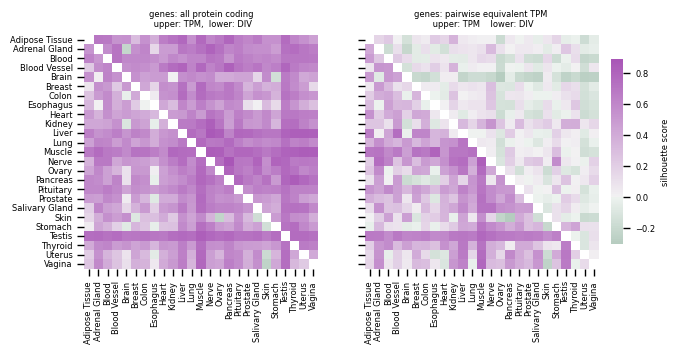

In [ ]:
import matplotlib.colors as mcolors

c_mapp = sns.diverging_palette(145, 300, s=60, as_cmap=True) # green to purple


allgenes_df = make_combined_trui_tril(metric_='silhouette_all_', baseon_ = 'SMTS')
nonDE = make_combined_trui_tril(metric_='silhouette_tpm_eq_', baseon_ = 'SMTS')
vmin = min([allgenes_df.min().min(), nonDE.min().min()])
vmax = max([allgenes_df.max().max(), nonDE.max().max()])

# allgenes_df.to_csv(tissue_pairwise_overview_path + 'SMTS_silh.allgenes.csv.gz', compression='gzip', index=True)
# nonDE.to_csv(tissue_pairwise_overview_path + 'SMTS_silh.eqTPM.csv.gz', compression='gzip', index=True)
allgenes_df.to_csv(tables_main_path + 'SMTS_silh.allgenes.csv.gz', compression='gzip', index=True)
nonDE.to_csv(tables_main_path + 'SMTS_silh.eqTPM.csv.gz', compression='gzip', index=True)



fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(8,8))

hm1 = sns.heatmap(allgenes_df.loc[allgenes_df.columns],center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax,ax = ax[0])
ax[0].set_title('genes: all protein coding\n upper: TPM,  lower: DIV')

hm2 = sns.heatmap(nonDE.loc[nonDE.columns], center=0,
                  cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax, ax = ax[1])
ax[1].set_title('genes: pairwise equivalent TPM \n upper: TPM    lower: DIV')
cbar = plt.colorbar(mappable=hm2.collections[0], ax=ax, shrink = 0.3, aspect=15, pad=0.02, label='silhouette score')
cbar.outline.set_visible(False)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.SMTS.png', format='png', dpi=300, bbox_inches='tight')




[Text(0.05, 0.5, 'Adipose'),
 Text(0.05, 1.5, 'Adrenal G.'),
 Text(0.05, 2.5, 'Blood'),
 Text(0.05, 3.5, 'Blood V.'),
 Text(0.05, 4.5, 'Brain'),
 Text(0.05, 5.5, 'Breast'),
 Text(0.05, 6.5, 'Colon'),
 Text(0.05, 7.5, 'Esophagus'),
 Text(0.05, 8.5, 'Heart'),
 Text(0.05, 9.5, 'Kidney'),
 Text(0.05, 10.5, 'Liver'),
 Text(0.05, 11.5, 'Lung'),
 Text(0.05, 12.5, 'Muscle'),
 Text(0.05, 13.5, 'Nerve'),
 Text(0.05, 14.5, 'Ovary'),
 Text(0.05, 15.5, 'Pancreas'),
 Text(0.05, 16.5, 'Pituitary'),
 Text(0.05, 17.5, 'Prostate'),
 Text(0.05, 18.5, 'Salivary G.'),
 Text(0.05, 19.5, 'Skin'),
 Text(0.05, 20.5, 'Stomach'),
 Text(0.05, 21.5, 'Testis'),
 Text(0.05, 22.5, 'Thyroid'),
 Text(0.05, 23.5, 'Uterus'),
 Text(0.05, 24.5, 'Vagina')]

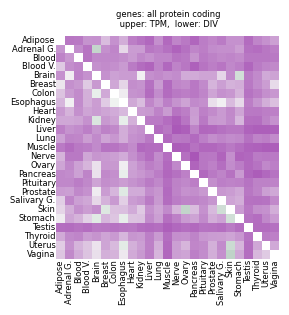

In [20]:
fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2.9,2.9))
hm1 = sns.heatmap(allgenes_df.loc[allgenes_df.columns],center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_title('genes: all protein coding\n upper: TPM,  lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)

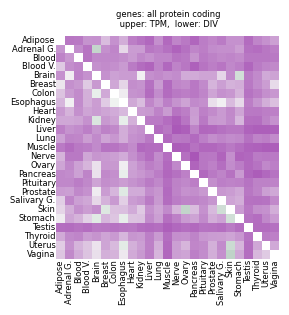

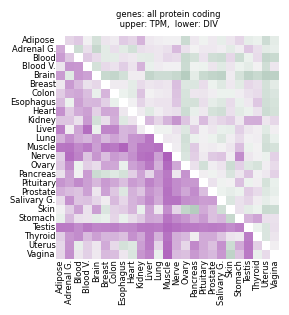

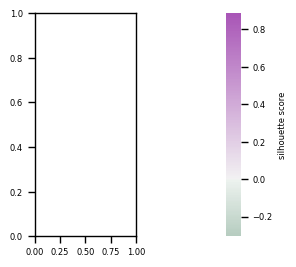

In [25]:
c_mapp = sns.diverging_palette(145, 300, s=60, as_cmap=True) # green to purple
abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}

allgenes_df = make_combined_trui_tril(metric_='silhouette_all_', baseon_ = 'SMTS')
nonDE = make_combined_trui_tril(metric_='silhouette_tpm_eq_', baseon_ = 'SMTS')
vmin = min([allgenes_df.min().min(), nonDE.min().min()])
vmax = max([allgenes_df.max().max(), nonDE.max().max()])

allgenes_df = allgenes_df.loc[allgenes_df.columns].rename(index = abb_SMTS, columns=abb_SMTS)
nonDE = nonDE.loc[nonDE.columns].rename(index = abb_SMTS, columns=abb_SMTS)

fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2.9,2.9))
hm1 = sns.heatmap(allgenes_df.loc[allgenes_df.columns],center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_title('genes: all protein coding\n upper: TPM,  lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.allgenes_df.SMTS.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2.9,2.9))
hm1 = sns.heatmap(nonDE.loc[nonDE.columns],center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_title('genes: all protein coding\n upper: TPM,  lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.nonDE.SMTS.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2.9,2.9))
cbar = plt.colorbar(mappable=hm1.collections[0], ax=ax, aspect=15, pad=0.4, label='silhouette score')
cbar.outline.set_visible(False)


fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.cbar.SMTS.png', format='png', dpi=300, bbox_inches='tight')

In [ ]:
''' supplementary data 2 ''' 
supplementary_path = 'tables_main/'
smts_overview_df[['t1','t2'] + ['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']].rename(columns = dict(zip(['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div'],['all genes (TPM)','all genes (I-DIV)', 'nonDE (TPM)','nonDE (I-DIV)']))).to_csv(supplementary_path + 'fig2_SMTS_silh.csv.gz')

''' supplementary data 3 ''' 
brain_overview_df[['t1','t2'] + ['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']].rename(columns = dict(zip(['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div'],['all genes (TPM)','all genes (I-DIV)', 'nonDE (TPM)','nonDE (I-DIV)']))).to_csv(supplementary_path + 'fig2_SMTS_silh.csv.gz')

 across SMTS tissues 
wilcoxon test between silhouette_all_tpm (all genes TPM) VS silhouette_all_div (all genes I-DIV)
results: 
S=2753.0,  p=1.12x10^-39
silhouette all div median: 0.51
silhouette all tpm median: 0.63
 across SMTS tissues 
wilcoxon test between silhouette_all_tpm (all genes TPM) VS silhouette_all_div (all genes I-DIV)
results: 
S=1363.0,  p=3.48x10^-45
silhouette tpm eq div median: 0.40
silhouette tpm eq tpm median: 0.02



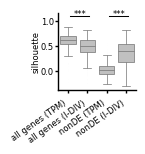

In [ ]:
median_per_group = smts_overview_df.melt(value_vars=['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']).groupby('variable')['value'].median()


fig, ax = plt.subplots(figsize=(1,1))
sns.boxplot(data = smts_overview_df.melt(value_vars=['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']), 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1},
            fliersize=0.75, linewidth=0.5,
            x = 'variable', y = 'value', color = 'silver')
# sns.swarmplot(data = smts_overview_df.melt(value_vars=['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']), 
#             x = 'variable', y = 'value', color='dimgrey', edgecolor='None', s=1, alpha = 0.5)
ax.set_xticklabels(['all genes (TPM)','all genes (I-DIV)', 'nonDE (TPM)','nonDE (I-DIV)'], rotation=35, ha='right')
ax.set_ylabel('silhouette')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set_xlabel('')

iinfo = ''
s, p = st.wilcoxon(smts_overview_df['silhouette_all_tpm'],smts_overview_df['silhouette_all_div'])
ax.axhline(y = 1.1, xmin=0.15,xmax=0.4,color='k',linewidth = 0.75)
iinfo += f''' across SMTS tissues 
wilcoxon test between silhouette_all_tpm (all genes TPM) VS silhouette_all_div (all genes I-DIV)
results: 
S={s},  {annotpval(p)}
'''
for idx in ['silhouette_all_div', 'silhouette_all_tpm']:
    iinfo += idx.replace('_', ' ') + ' median: ' + f'{median_per_group.loc[idx]:.2f}' + '\n'

ax.text(y=1.1, x = 0.3, s = pval_to_asterisks(p))
s, p = st.wilcoxon(smts_overview_df['silhouette_tpm_eq_tpm'],smts_overview_df['silhouette_tpm_eq_div'])
ax.axhline(y = 1.1, xmin=0.65,xmax=0.9,color='k',linewidth = 0.75)
ax.text(y=1.1, x = 2.3, s = pval_to_asterisks(p))
iinfo += f''' across SMTS tissues 
wilcoxon test between silhouette_tpm_eq_tpm (nonDE genes on TPM) VS silhouette_tpm_eq_div (nonDE genes on I-DIV)
results: 
S={s},  {annotpval(p)}
'''

for idx in ['silhouette_tpm_eq_div', 'silhouette_tpm_eq_tpm']:
    iinfo += idx.replace('_', ' ') + ' median: ' + f'{median_per_group.loc[idx]:.2f}' + '\n'

sns.despine()


print(iinfo)
with open('figs_limma_equivalence/SMTS_sil_overview.about.txt', 'w') as file:
    file.write(iinfo)
    file.close()
fig.savefig('figs_limma_equivalence/' + 'SMTS_sil_overview.png', format='png', dpi=300, bbox_inches='tight')

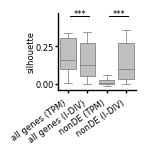

In [ ]:

fig, ax = plt.subplots(figsize=(1,1))
sns.boxplot(data = brain_overview_df.melt(value_vars=['silhouette_all_tpm','silhouette_all_div', 'silhouette_tpm_eq_tpm', 'silhouette_tpm_eq_div']), 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1},
            fliersize=0.75, linewidth=0.5,
            x = 'variable', y = 'value', color = 'silver')
ax.set_xticklabels(['all genes (TPM)','all genes (I-DIV)', 'nonDE (TPM)','nonDE (I-DIV)'], rotation=35, ha='right')
ax.set_ylabel('silhouette')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set_xlabel('')

iinfo = ''


s, p = st.wilcoxon(brain_overview_df['silhouette_all_tpm'],brain_overview_df['silhouette_all_div'])
ax.axhline(y = 0.9, xmin=0.15,xmax=0.4,color='k',linewidth = 0.75)
ax.text(y=0.9, x = 0.3, s = pval_to_asterisks(p))
iinfo += f''' across brain SMTSD tissues 
wilcoxon test between silhouette_all_tpm (all genes TPM) VS silhouette_all_div (all genes I-DIV)
results: 
{s},  {p}
'''


s, p = st.wilcoxon(brain_overview_df['silhouette_tpm_eq_tpm'],brain_overview_df['silhouette_tpm_eq_div'])
ax.axhline(y = 0.9, xmin=0.65,xmax=0.9,color='k',linewidth = 0.75)
ax.text(y=0.9, x = 2.3, s = pval_to_asterisks(p))

iinfo += f''' across SMTS tissues 
wilcoxon test between silhouette_tpm_eq_tpm (nonDE genes on TPM) VS silhouette_tpm_eq_div (nonDE genes on I-DIV)
results: 
{s},  {p}
'''
with open('figs_limma_equivalence/brainSMTSD_sil_overview.about.txt', 'w') as file:
    file.write(iinfo)
    file.close()

sns.despine()
fig.savefig('figs_limma_equivalence/' + 'brainSMTSD_sil_overview.png', format='png', dpi=300, bbox_inches='tight')

# SMTSD silhouette scores

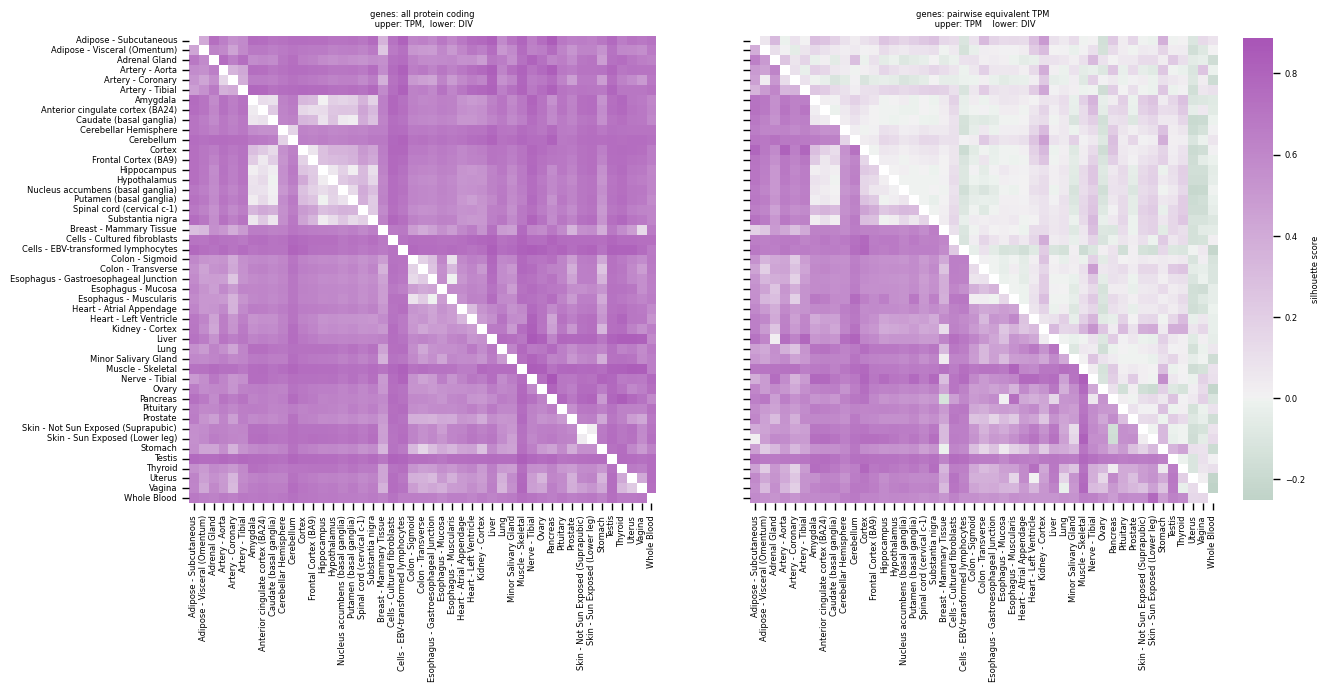

In [ ]:
import matplotlib.colors as mcolors

c_mapp = sns.diverging_palette(145, 300, s=60, as_cmap=True) # green to purple


allgenes_df = make_combined_trui_tril(metric_='silhouette_all_', baseon_ = 'SMTSD')
nonDE = make_combined_trui_tril(metric_='silhouette_tpm_eq_', baseon_ = 'SMTSD')
vmin = min([allgenes_df.min().min(), nonDE.min().min()])
vmax = max([allgenes_df.max().max(), nonDE.max().max()])

# allgenes_df.to_csv('tables_limma_equivalence/SMTSD_silh.allgenes.csv.gz', compression='gzip', index=True)
# nonDE.to_csv('tables_limma_equivalence/SMTSD_silh.eqTPM.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(4*4,5*4))

hm1 = sns.heatmap(allgenes_df.loc[allgenes_df.columns],center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax,ax = ax[0])
ax[0].set_title('genes: all protein coding\n upper: TPM,  lower: DIV')

hm2 = sns.heatmap(nonDE.loc[nonDE.columns], center=0,
                  cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax, ax = ax[1])
ax[1].set_title('genes: pairwise equivalent TPM \n upper: TPM    lower: DIV')
cbar = plt.colorbar(mappable=hm2.collections[0], ax=ax, shrink = 0.3, aspect=15, pad=0.02, label='silhouette score')
cbar.outline.set_visible(False)
ax[0].set_xticklabels([l.get_text().replace('Brain - ', '') for l in ax[0].get_xticklabels()])
ax[0].set_yticklabels([l.get_text().replace('Brain - ', '') for l in ax[0].get_yticklabels()])
ax[1].set_xticklabels([l.get_text().replace('Brain - ', '') for l in ax[1].get_xticklabels()])
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.SMTSD.png', format='png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'genes: all protein coding\n upper: TPM,  lower: DIV')

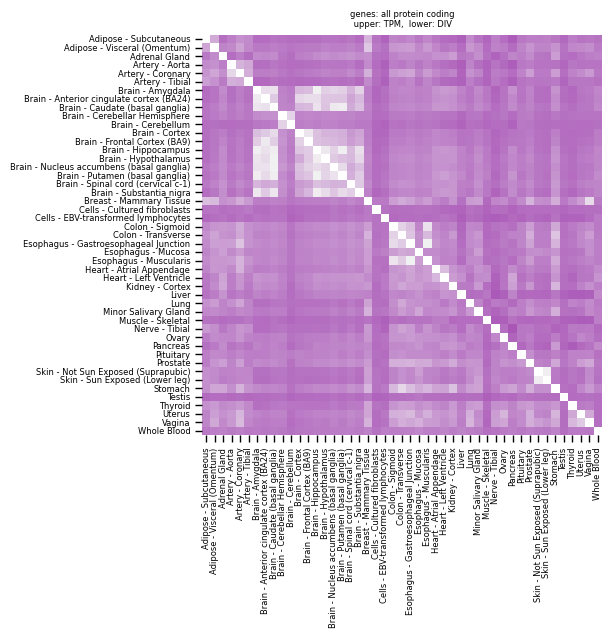

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5.2,5.2))


allgenes_df = allgenes_df.loc[allgenes_df.columns]
nonDE = nonDE.loc[nonDE.columns]
sns.heatmap(allgenes_df,center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_title('genes: all protein coding\n upper: TPM,  lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.allgenes_df.SMTSD.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5.2,5.2))
hm2 = sns.heatmap(nonDE,center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_title('genes: equivalent TPM \n upper: TPM    lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.nonDE.SMTSD.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5.2,5.2))
cbar = plt.colorbar(mappable=hm2.collections[0], ax=ax, aspect=15, pad=0.4, label='silhouette score')
cbar.outline.set_visible(False)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.cbar.SMTSD.png', format='png', dpi=300, bbox_inches='tight')

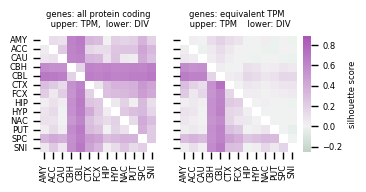

In [ ]:
allgenes_df = make_combined_trui_tril(metric_='silhouette_all_', baseon_ = 'SMTSD')
nonDE = make_combined_trui_tril(metric_='silhouette_tpm_eq_', baseon_ = 'SMTSD')

vmin = min([allgenes_df.min().min(), nonDE.min().min()])
vmax = max([allgenes_df.max().max(), nonDE.max().max()])
# norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(4,5))

hm1 = sns.heatmap(allgenes_df.filter(like='Brain').loc[allgenes_df.filter(like='Brain').columns], center=0,
                  cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax,ax = ax[0])
ax[0].set_title('genes: all protein coding\n upper: TPM,  lower: DIV')

hm2 = sns.heatmap(nonDE.filter(like='Brain').loc[nonDE.filter(like='Brain').columns], center=0,
                  cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax, ax = ax[1])
ax[1].set_title('genes: equivalent TPM \n upper: TPM    lower: DIV')
cbar = plt.colorbar(mappable=hm2.collections[0], ax=ax, shrink = 0.3, aspect=15, pad=0.02, label='silhouette score')
cbar.outline.set_visible(False)

ax[0].set_xticklabels([brain_regions_abb[l.get_text()] for l in ax[0].get_xticklabels()], fontsize=6)
ax[0].set_yticklabels([brain_regions_abb[l.get_text()] for l in ax[0].get_yticklabels()], fontsize=6)
ax[1].set_xticklabels([brain_regions_abb[l.get_text()] for l in ax[1].get_xticklabels()], fontsize=6)
# ax[0].set_xticklabels(ax[0].get_xticklabels(), fontsize=6)
# fig.suptitle('Pairwise silhouette scores', y=0.7, x= 0.45,)
for i in [0,1]:
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['bottom'].set_visible(False)
    ax[i].spines['left'].set_visible(False)     
    ax[i].patch.set_facecolor('None')

fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.SMTSD_brain.png', format='png', dpi=300, bbox_inches='tight')

allgenes_df.filter(like='Brain').loc[allgenes_df.filter(like='Brain').columns].to_csv(tables_main_path + 'SMTSDbrain_silh.allgenes.csv.gz', compression='gzip', index=True)
nonDE.filter(like='Brain').loc[nonDE.filter(like='Brain').columns].to_csv(tables_main_path + 'SMTSDbrain_silh.eqTPM.csv.gz', compression='gzip', index=True)


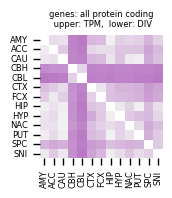

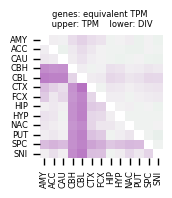

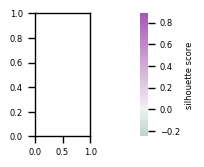

In [ ]:
allgenes_df = make_combined_trui_tril(metric_='silhouette_all_', baseon_ = 'SMTSD')
nonDE = make_combined_trui_tril(metric_='silhouette_tpm_eq_', baseon_ = 'SMTSD')

vmin = min([allgenes_df.min().min(), nonDE.min().min()])
vmax = max([allgenes_df.max().max(), nonDE.max().max()])
c_mapp = sns.diverging_palette(145, 300, s=60, as_cmap=True) # green to purple

fig, ax = plt.subplots(nrows=1, ncols=1, sharey=True, figsize=(1.6,1.6))
sns.heatmap(allgenes_df.filter(like='Brain').loc[allgenes_df.filter(like='Brain').columns], center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_xticklabels([brain_regions_abb[l.get_text()] for l in ax.get_xticklabels()])
ax.set_yticklabels([brain_regions_abb[l.get_text()] for l in ax.get_yticklabels()])
ax.set_title('genes: all protein coding\n upper: TPM,  lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.allgenes_df.SMTSD_brain.png', format='png', dpi=300, bbox_inches='tight')


fig, ax = plt.subplots(nrows=1, ncols=1, sharey=True, figsize=(1.6,1.6))
hm2=sns.heatmap(nonDE.filter(like='Brain').loc[nonDE.filter(like='Brain').columns], center=0,cmap=c_mapp, square=True, cbar=False, vmin=vmin, vmax=vmax)
ax.set_xticklabels([brain_regions_abb[l.get_text()] for l in ax.get_xticklabels()])
ax.set_yticklabels([brain_regions_abb[l.get_text()] for l in ax.get_yticklabels()])
ax.set_title('genes: equivalent TPM \n upper: TPM    lower: DIV')
ax.tick_params(left=False, bottom=False) ## other options are right and top
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.nonDE.SMTSD_brain.png', format='png', dpi=300, bbox_inches='tight')


fig, ax = plt.subplots(nrows=1, ncols=1, sharey=True, figsize=(1.6,1.6))
cbar = plt.colorbar(mappable=hm2.collections[0], ax=ax, aspect=15, pad=0.4, label='silhouette score')
cbar.outline.set_visible(False)
fig.savefig(pth + 'figs_limma_equivalence/pairwise_silh.cbar.SMTSD_brain.png', format='png', dpi=300, bbox_inches='tight')

## SMTS specific exampels

In [12]:
genes_lists = make_gene_list(basedon='SMTS', idx_tissuepair=226, what_to_return = 'genes')

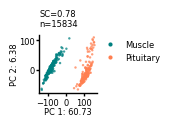

In [13]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['all'],sample_list=metadata.loc[metadata.SMTS.isin(genes_lists['SMTS'])].index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(226),'SMTS', 'tpm', 'all']))


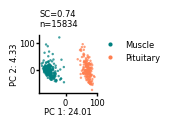

In [14]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['all'],sample_list=metadata.loc[metadata.SMTS.isin(genes_lists['SMTS'])].index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(226),'SMTS', 'div', 'all']))

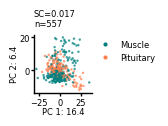

In [15]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['tpm_eq'],sample_list=metadata.loc[metadata.SMTS.isin(genes_lists['SMTS'])].index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(226),'SMTS', 'tpm', 'tpm_eq']))

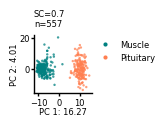

In [16]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['tpm_eq'],sample_list=metadata.loc[metadata.SMTS.isin(genes_lists['SMTS'])].index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(226),'SMTS', 'div', 'tpm_eq']))

## SMTSD specific examples

In [84]:
idx_pair = 416

In [85]:
# genes_lists = make_gene_list(basedon='SMTSD', idx_tissuepair=341, what_to_return = 'genes')
genes_lists = make_gene_list(basedon='SMTSD', idx_tissuepair=idx_pair, what_to_return = 'genes')

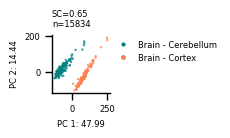

In [92]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['all'], sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].drop(index='GTEX-Q2AG-2926-SM-2HMJ3').index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'tpm', 'all']))


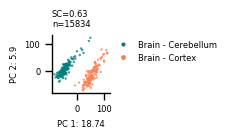

In [93]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['all'], sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].drop(index='GTEX-Q2AG-2926-SM-2HMJ3').index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'div', 'all']))


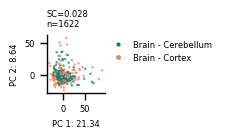

In [94]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['tpm_eq'], sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].drop(index='GTEX-Q2AG-2926-SM-2HMJ3').index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'tpm', 'tpm_eq']))


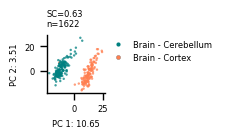

In [95]:
pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['tpm_eq'], sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].drop(index='GTEX-Q2AG-2926-SM-2HMJ3').index)
plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'div', 'tpm_eq']))

# differential I-DIV & differential TPM using limma in tissue pair

In [17]:
pair_columns = metadata.loc[metadata.SMTSD.isin(smtsd_overview_df.loc[smtsd_overview_df.pair_index == 416, ['t1', 't2']].values[0])].index

In [ ]:
pair_columns = metadata.loc[metadata.SMTSD.isin(smtsd_overview_df.loc[smtsd_overview_df.pair_index == 416, ['t1', 't2']].values[0])].index
pair_div = div[pair_columns]
filt_genes = pair_div.median(axis='columns')[pair_div.median(axis='columns') > 0].index
del pair_div

In [ ]:
basedon = 'SMTSD' ; idx_tissuepair = 416
input_path = tissue_pairwise_overview_path + f'{basedon}_limma/'
filenames_dict = {}
filenames_dict['div'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.div.limma_DE_equiv.csv.gz'))][0]
filenames_dict['tpm'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.tpm.limma_DE_equiv.csv.gz'))][0]

div_limma = pd.read_csv(input_path + filenames_dict['div'], compression='gzip', index_col='gene')
tpm_limma = pd.read_csv(input_path + filenames_dict['tpm'], compression='gzip', index_col='gene')

div_limma = div_limma.loc[filt_genes]
tpm_limma = tpm_limma.loc[filt_genes]

div_limma = div_limma.assign(**{'-log10(adj.P.Val)': -np.log10(div_limma['adj.P.Val']) })
tpm_limma = tpm_limma.assign(**{'-log10(adj.P.Val)': -np.log10(tpm_limma['adj.P.Val']) })

div_limma = div_limma.join(gene_info.gene_name)
tpm_limma = tpm_limma.join(gene_info.gene_name)


In [ ]:

def plot_pairwise_PCA(savefig = False, filename=''):
    
    h = pca_result.drop(columns=[0,1]).columns[0]#SMTS or SMTSD
    
    t1, t2 = genes_lists[h]
    cplt = {t1: 'Teal', t2: 'Coral'}
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(0.75,0.75))
    sns.scatterplot(data= pca_result, x=0, y=1, alpha=0.75, s=3, edgecolor='None',hue= h, 
                    palette=cplt, ax = ax)
    ax.set(xlabel = 'PC 1: ' + str(round(var1*100,2)), 
        ylabel='PC 2: ' + str(round(var2*100,2)))
    ax.set_title(f'SC={silhouette_sc:.2}' + f'\nn={len(loadings)}', loc='left')
    # ax.tick_params(left=False, bottom=False) ## other options are right and top
    ax.tick_params(length=2.5) ## other options are right and top
    ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
    ax.set_xlabel('PC 1: ' + str(round(var1*100,2)),labelpad=0)
    ax.set_ylabel('PC 2: ' + str(round(var2*100,2)),labelpad=0)

    legend_handles = [
        Line2D([], [], marker='o', linestyle='None', markerfacecolor=cplt[t1],markeredgewidth=0.25,
            markeredgecolor='none', markersize=3, label=t1),
        Line2D([], [], marker='o', linestyle='None', markerfacecolor=cplt[t2],markeredgewidth=0.25,
            markeredgecolor='none', markersize=3, label=t2),
    ]
    ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
    sns.despine()
    
    if savefig: 
        # fig.savefig(pth + f'figs_limma_equivalence/pca.{filename}.png', format='png', dpi=300, bbox_inches='tight')
        fig.savefig(pth + f'figs_limma_equivalence/SMTSD/{idx_pair}/pca.{filename}.png', format='png', dpi=300, bbox_inches='tight')


Brain - Cerebellum


In [ ]:
def remove_outliers_pca(pca_df):
    # Remove rows with outliers in either PCA component using the 1.5×IQR rule
    q1 = pca_df[[0, 1]].quantile(0.15)
    q3 = pca_df[[0, 1]].quantile(0.95)
    iqr = q3 - q1

    inlier_mask = ~(
        (pca_df[[0, 1]] < (q1 - 1.5 * iqr)) |
        (pca_df[[0, 1]] > (q3 + 1.5 * iqr))
    ).any(axis=1)

    pca_df = pca_df.loc[inlier_mask].copy()
    return pca_df

In [ ]:
''' logFC = log2(expression in ppair[2]) − log2(expression in ppair[1]) 
So in the output:
Positive logFC → higher expression in d$t2 (the second tissue in the pair) relative to d$t1
Negative logFC → higher expression in d$t1 relative to d$t2
''' 

tables_path = f'tables_limma_equivalence/'
if not os.path.isdir(tables_path):
    os.mkdir(tables_path)


basedon = 'SMTSD'
for idx_pair in [265, 303, 387, 385, 341, 386, 422, 417, 419, 381, 418, 423, 380, 342, 416, 383, 382, 420, 421, 264, 304, 384]:

    pair_columns = metadata.loc[metadata.SMTSD.isin(smtsd_overview_df.loc[smtsd_overview_df.pair_index == idx_pair, ['t1', 't2']].values[0])].index
    pair_div = div[pair_columns]
    filt_genes = pair_div.median(axis='columns')[pair_div.median(axis='columns') > 0].index
    del pair_div    
    
    input_path = tissue_pairwise_overview_path + f'{basedon}_limma/'
    filenames_dict = {}
    filenames_dict['div'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.div.limma_DE_equiv.csv.gz'))][0]
    filenames_dict['tpm'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.tpm.limma_DE_equiv.csv.gz'))][0]

    div_limma = pd.read_csv(input_path + filenames_dict['div'], compression='gzip', index_col='gene')
    tpm_limma = pd.read_csv(input_path + filenames_dict['tpm'], compression='gzip', index_col='gene')

    t1, t2 = filenames_dict['div'].split('.')[1:3]
    cplt = {t1: 'Teal', t2: 'Coral'}

    div_limma = div_limma.loc[filt_genes]
    tpm_limma = tpm_limma.loc[filt_genes]

    div_limma = div_limma.assign(**{'-log10(adj.P.Val)': -np.log10(div_limma['adj.P.Val']) })
    tpm_limma = tpm_limma.assign(**{'-log10(adj.P.Val)': -np.log10(tpm_limma['adj.P.Val']) })

    div_limma = div_limma.join(gene_info.gene_name)
    tpm_limma = tpm_limma.join(gene_info.gene_name)

    outputpath = pth + f'figs_limma_equivalence/{basedon}/' 
    if not os.path.isdir(outputpath):
        os.mkdir(outputpath)
    outputpath_raw = outputpath+ str(idx_pair) + '/'
    if not os.path.isdir(outputpath_raw):
        os.mkdir(outputpath_raw)
    tables_path_idx = 'tables_limma_equivalence/' + 'SMTSD_' + str(idx_pair) + '/'
    if not os.path.isdir(tables_path_idx):
        os.mkdir(tables_path_idx)


    ''' logFCs scatterplots '''
    logfc_df = div_limma[['logFC','adj.P.Val']].add_suffix('_div').join(tpm_limma[['logFC','adj.P.Val']].add_suffix('_tpm'))


    fig, ax = plt.subplots(figsize=(1,1))
    sns.scatterplot(data = logfc_df, x = 'logFC' + '_tpm', y='logFC' + '_div', edgecolor=None, color='dimgrey', alpha=0.1, s=3,ax=ax)
    r, p = st.spearmanr(logfc_df['logFC' + '_tpm'], logfc_df['logFC' + '_div'])
    ax.set_title(', '.join([f'ρ={r:.2f}' ,'p=' + format_small_number(p)]))
    ax.tick_params(length=2.5) 
    ax.set_yticklabels(ax.get_yticklabels(),x=0)
    ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0)
    ax.set_xlabel(ax.get_xlabel(),labelpad=0)
    ax.set_ylabel(ax.get_ylabel(),labelpad=0)
    ax.set(xlabel = '∆ TPM', ylabel = '∆ I-DIV')
    fig.savefig(outputpath_raw + f'Deltas.n_{len(filt_genes)}.scatter.png', format='png', dpi=300, bbox_inches='tight')

    sns.rugplot(data = logfc_df, x = 'logFC' + '_tpm', y='logFC' + '_div', color='dimgrey', alpha = 0.05, height=.03, lw=0.2)
    fig.savefig(outputpath_raw + f'Deltas.n_{len(filt_genes)}_rug.scatter.png', format='png', dpi=300, bbox_inches='tight')
    s = f'''
    I used spermanr test
    r={r}, p={p}
    '''

    with open(outputpath_raw + 'Deltas.about.txt', 'w') as f:
        f.write(s)
        f.close()

    logfc_df.to_csv(tables_path_idx + 'logFCs.csv.gz', compression='gzip', index=True)
    labels_dict = {'div': 'I-DIV', 'tpm': 'TPM' }
    enrichr_res = {}
    
    
    genes_lists = make_gene_list(basedon='SMTSD', idx_tissuepair=idx_pair, what_to_return = 'genes')

    pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['all'],sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].index)
    pca_result = remove_outliers_pca(pca_df=pca_result)
    plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'tpm', 'all']))
    pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['all'],sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].index)
    pca_result = remove_outliers_pca(pca_df=pca_result)
    plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'div', 'all']))    
    pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, gene_list = genes_lists['tpm_eq'],sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].index)
    pca_result = remove_outliers_pca(pca_df=pca_result)
    plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'tpm', 'tpm_eq']))
    pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, gene_list = genes_lists['tpm_eq'],sample_list=metadata.loc[metadata.SMTSD.isin(genes_lists['SMTSD'])].index)
    pca_result = remove_outliers_pca(pca_df=pca_result)
    plot_pairwise_PCA(savefig=True, filename='.'.join([str(idx_pair),'SMTSD', 'div', 'tpm_eq']))    
    
    
    for m in ['div', 'tpm']:
        
        df = globals()[m + '_limma'].copy()
        
        if m == 'div':
            filtlogfc_up = 0.05
            filtlogfc_down = -0.05
            adjP_cutoff = 0.05 # 1e-10
        if m == 'tpm':
            filtlogfc_up = 1
            filtlogfc_down = -1
            adjP_cutoff = 1e-3 # 1e-10
        cutoff = f'minlogFC{filtlogfc_up}_pval{adjP_cutoff}'
        limma_dfs = {}
        limma_dfs[t2 + ' up'] = df.loc[(df['classification'] == 'differentially_expressed') & (df['adj.P.Val'] <= adjP_cutoff)& (df.logFC >= filtlogfc_up)]
        limma_dfs[t1 + ' up'] = df.loc[(df['classification'] == 'differentially_expressed') & (df['adj.P.Val'] <= adjP_cutoff)& (df.logFC <= filtlogfc_down)]
        limma_genes = {}
        limma_genes[t2 + ' up'] = limma_dfs[t2 + ' up'].gene_name.to_list()
        limma_genes[t1 + ' up'] = limma_dfs[t1 + ' up'].gene_name.to_list()
        
        
        outputpath = outputpath_raw + m + '/'
        if not os.path.isdir(outputpath):
            os.mkdir(outputpath)
        
        
        fig, ax = plt.subplots(figsize=(1,1))
        sns.scatterplot(data = df, x = 'logFC', y = '-log10(adj.P.Val)', c = 'silver', edgecolor=None, s=3, zorder =1)
        sns.scatterplot(data = limma_dfs[t2 + ' up'], x = 'logFC', y = '-log10(adj.P.Val)', c = cplt[t2], edgecolor=None, s=3, zorder=2)
        sns.scatterplot(data = limma_dfs[t1 + ' up'], x = 'logFC', y = '-log10(adj.P.Val)', c = cplt[t1], edgecolor=None, s=3, zorder=2)
        ax.set(xlabel= ' '.join(['∆',m]), ylabel = '-log10(Adj.P)')
        
        ax.tick_params(length=2.5) ## other options are right and top
        ax.set_yticklabels(ax.get_yticklabels(),x=0)
        ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0)
        ax.set_xlabel(ax.get_xlabel(),labelpad=0)
        ax.set_ylabel(ax.get_ylabel(),labelpad=0)

        sns.despine()
        fig.savefig(outputpath + 'volcano' + f'.cutoff_{cutoff}.png', format='png', dpi=300, bbox_inches='tight')
        plt.close()
        s = f''' {idx_pair}
        ngenes Positive ∆ {len(limma_genes[t2 + ' up'])} -> higher {labels_dict[m]} in {t2}
        ngenes Negative ∆ {len(limma_genes[t1 + ' up'])} -> higher {labels_dict[m]} in {t1}
        out of {len(df)} genes
        '''
        print(s)
        with open(outputpath + f'gene_count.cutoff_{cutoff}.txt', 'w') as file:
            file.write(s)
            file.close()
            
        enrichr_res[m] = pd.concat([do_enrichr(gene_list = limma_genes[k], bachground_genelist = df.gene_name.to_list(), trend = k) for k in limma_genes.keys()])
        enrichr_res[m].to_csv(tables_path_idx + f'enrichr.cutoff_{cutoff}.{m}.csv.gz', compression='gzip', index=True)

        for k in enrichr_res[m].trend.unique():
            trend_df = enrichr_res[m][(enrichr_res[m]['Adjusted P-value'] < 0.05) & (enrichr_res[m]['Gene_set'] == 'GO_Biological_Process_2025') & (enrichr_res[m]['trend'] == k)].head(10)
            if len(trend_df) > 0: 
                fig, ax = plt.subplots(figsize=(0.75,len(trend_df)/6.67 ))
                sns.scatterplot(data = trend_df, x = '-log10(Adjusted P-value)', y= 'Term', c = cplt[' '.join(k.split(' ')[:-1])], edgecolor=None, size='nGenesTerm', sizes=(10,40), zorder = 6)
                ax.legend(bbox_to_anchor = (1.2,1.2))
                
                yaxis_labels = [y.get_text() for y in ax.get_yticklabels()]
                labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
                
                labels= []
                for i, label in enumerate(labels_raw):
                    
                    if yaxis_labels[i] in trend_df.Term.unique():
                        labels += [label + f' (n={list(trend_df.loc[trend_df.Term == yaxis_labels[i], "nGenesTerm"])[0]})']
                    else:
                        labels += [label]
                
                ax.set_yticklabels(labels)
                ax.set_yticklabels(abbreviate_go_terms(l) for l in labels)
                ax.set(ylabel='Biological Process', xlabel = '-log10(Adj.P)', title = k)

                ax.tick_params(length=2.5) 
                ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
                ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
                ax.set_xlabel(ax.get_xlabel(),labelpad=0)
                ax.set_ylabel(ax.get_ylabel(),labelpad=0)   
                ax.set_xlim(ax.set_xlim()[0] * 0.9, ax.set_xlim()[1] * 1.1 )
                sns.despine()
                fig.savefig(outputpath + k + f'.cutoff_{cutoff}.png', format='png', dpi=300, bbox_inches='tight')
                plt.close()
    
    
    ''' compare number of significant terms per pair'''    
    enrichr = pd.concat([enrichr_res['div'].assign(metric='I-DIV'),enrichr_res['tpm'].assign(metric='TPM') ])
    enrichr = enrichr.loc[(enrichr['Adjusted P-value'] <= 0.05) & (enrichr['nGenesTerm'] >= 5) ]

    for ti in [t1, t2]:
        t = ti + ' up'
        venn_s = enrichr.loc[enrichr.trend == t].metric.value_counts()
        if len(venn_s) > 1:
            venn_s.loc['intersect'] = len(np.intersect1d(enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='TPM')].Term.unique(), enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='I-DIV')].Term.unique()))
            venn_s.name = ti
            venn_s.astype(int)
            
            fig, ax = plt.subplots(figsize=(1,1))
            v = venn2(subsets=venn_s, set_labels=venn_s.drop('intersect').index, set_colors=('silver', 'skyblue'),ax=ax)
            for text in v.set_labels:
                if text:
                    text.set_fontsize(6)
            for text in v.subset_labels:
                if text:
                    text.set_fontsize(6)
                
        fig.savefig(outputpath_raw + f'TermCount.{t.replace(' ', '_')}.png', format='png', dpi=300, bbox_inches='tight')
        venn_s.to_csv(tables_path_idx + '.'.join(['venn',t.replace(' ', '_'), 'csv', 'gz']), compression='gzip', index=True)

 265
        ngenes Positive logFC 7541 -> higher I-DIV in Brain - Cerebellum
        ngenes Negative logFC 1323 -> higher I-DIV in Brain - Amygdala
        out of 13218 genes
        
 303
        ngenes Positive logFC 5936 -> higher I-DIV in Brain - Cerebellar Hemisphere
        ngenes Negative logFC 1813 -> higher I-DIV in Brain - Anterior cingulate cortex (BA24)
        out of 13193 genes
        
 387
        ngenes Positive logFC 2033 -> higher I-DIV in Brain - Substantia nigra
        ngenes Negative logFC 6076 -> higher I-DIV in Brain - Cerebellar Hemisphere
        out of 13173 genes
        
 385
        ngenes Positive logFC 1835 -> higher I-DIV in Brain - Putamen (basal ganglia)
        ngenes Negative logFC 6336 -> higher I-DIV in Brain - Cerebellar Hemisphere
        out of 13149 genes
        
 341
        ngenes Positive logFC 5558 -> higher I-DIV in Brain - Cerebellar Hemisphere
        ngenes Negative logFC 2154 -> higher I-DIV in Brain - Caudate (basal ganglia)
     

In [ ]:
pivot_per_pair = {}
pivot_per_smtsdbrain = {}

m = 'div'
df=pd.concat([pd.read_csv(f'tables_limma_equivalence/SMTSD_{idx_pair}/' + f'enrichr.cutoff_minlogFC0.05_pval0.05.div.csv.gz').drop(columns='Unnamed: 0').assign(pair=idx_pair)for idx_pair in [265, 303, 387, 385, 341, 386, 422, 417, 419, 381, 418, 423, 380, 342, 416, 383, 382, 420, 421, 264, 304, 384]])
df = df.loc[(df.Gene_set == 'GO_Biological_Process_2025') & (df['Adjusted P-value'] <= 0.05)]
pivot_per_pair[m] = df.pivot_table(index = 'Term', columns='pair', values = '-log10(Adjusted P-value)')
pivot_per_smtsdbrain[m] = df.pivot_table(index = 'Term', columns='trend', values = '-log10(Adjusted P-value)')

m = 'tpm'
df=pd.concat([pd.read_csv(f'SMTSD_{idx_pair}/' + 'enrichr.cutoff_minlogFC1_pval0.001.tpm.csv.gz').drop(columns='Unnamed: 0').assign(pair=idx_pair)for idx_pair in [265, 303, 387, 385, 341, 386, 422, 417, 419, 381, 418, 423, 380, 342, 416, 383, 382, 420, 421, 264, 304, 384]])
df = df.loc[(df.Gene_set == 'GO_Biological_Process_2025') & (df['Adjusted P-value'] <= 0.05)]
pivot_per_pair[m] = df.pivot_table(index = 'Term', columns='pair', values = '-log10(Adjusted P-value)')
pivot_per_smtsdbrain[m] = df.pivot_table(index = 'Term', columns='trend', values = '-log10(Adjusted P-value)')

In [31]:
df_to_dict = brain_overview_df.set_index('pair_index')[['t1', 't2']]
df_to_dict['tissues'] = df_to_dict['t1'].astype(str) + ' & ' + df_to_dict['t1'].astype(str)
df_to_dict['tissues'] = df_to_dict['tissues'].str.replace('Brain - ', '')
pair_to_idx = df_to_dict['tissues'].to_dict()
del df_to_dict

In [32]:
brain_overview_df.set_index('pair_index')[['t1', 't2']]

,t1,t2
pair_index,,
262,Brain - Amygdala,Brain - Anterior cingulate cortex (BA24)
264,Brain - Amygdala,Brain - Cerebellar Hemisphere
272,Brain - Amygdala,Brain - Spinal cord (cervical c-1)
312,Brain - Anterior cingulate cortex (BA24),Brain - Substantia nigra
267,Brain - Amygdala,Brain - Frontal Cortex (BA9)
...,...,...
587,Brain - Nucleus accumbens (basal ganglia),Brain - Spinal cord (cervical c-1)
586,Brain - Nucleus accumbens (basal ganglia),Brain - Putamen (basal ganglia)
618,Brain - Putamen (basal ganglia),Brain - Substantia nigra


In [ ]:
m='div'
countna = pivot_per_pair[m][pivot_per_pair[m] >= -np.log10(0.05)].isna().sum(axis='columns').sort_values()
countna = countna[countna<len(pivot_per_pair[m].columns)]
pivot_per_pair[m] = pivot_per_pair[m][pivot_per_pair[m]>=-np.log10(0.05)].loc[countna.index]

drop_columns = pivot_per_pair[m].isna().sum(axis='rows')
drop_columns = drop_columns[drop_columns==len(pivot_per_pair[m])].index

pivot_per_pair[m].drop(columns=drop_columns, inplace=True )
pivot_per_pair[m].rename(columns = {c:pair_to_idx[c]  for c in pivot_per_pair[m].columns}, inplace=True)
pivot_per_pair[m].to_csv(f'tables_limma_equivalence/enrichr_overview_brainpairs.{m}.csv.gz', compression='gzip', index=True)
pivot_per_pair[m].to_csv(tables_main_path + f'/enrichr_overview_brainpairs.{m}.csv.gz', compression='gzip', index=True)


NameError: name 'tables_main_path' is not defined

In [ ]:
m='tpm'
countna = pivot_per_pair[m][pivot_per_pair[m] >= -np.log10(0.05)].isna().sum(axis='columns').sort_values()
countna = countna[countna<len(pivot_per_pair[m].columns)]
pivot_per_pair[m] = pivot_per_pair[m][pivot_per_pair[m]>=-np.log10(0.05)].loc[countna.index]

drop_columns = pivot_per_pair[m].isna().sum(axis='rows')
drop_columns = drop_columns[drop_columns==len(pivot_per_pair[m])].index

pivot_per_pair[m].drop(columns=drop_columns, inplace=True )
pivot_per_pair[m].rename(columns = {c:pair_to_idx[c]  for c in pivot_per_pair[m].columns}, inplace=True)
pivot_per_pair[m].to_csv(f'tables_limma_equivalence/enrichr_overview_brainpairs.{m}.csv.gz', compression='gzip', index=True)
pivot_per_pair[m].to_csv(tables_main_path + f'/enrichr_overview_brainpairs.{m}.csv.gz', compression='gzip', index=True)

pair,264,265,303,304,341,342,380,381,382,383,...,386,387,416,417,418,419,420,421,422,423
Term,,,,,,,,,,,,,,,,,,,,,
Regulation of Transcription by RNA Polymerase II (GO:0006357),22.310080,19.398688,29.912464,27.432845,21.814761,19.009259,30.982128,30.332945,22.067089,30.367553,...,9.150410,24.106196,24.374033,18.949218,21.333819,22.430246,19.353024,18.185363,5.408897,23.229852
Chromatin Organization (GO:0006325),10.671874,9.743809,14.480711,11.743456,13.497953,10.908476,11.395280,10.375353,11.258313,12.259494,...,5.953027,10.547668,10.337463,7.268415,10.894020,9.263229,9.186026,9.166617,3.843439,9.865152
Chromatin Remodeling (GO:0006338),10.580568,9.356700,11.214530,8.668129,13.893232,10.321866,8.288722,5.418888,11.629985,11.206483,...,6.230391,9.746413,6.785844,6.465919,10.894020,9.093704,9.186026,9.653158,4.647447,11.466442
Regulation of DNA-templated Transcription (GO:0006355),28.581855,22.528043,33.642103,27.811053,28.499770,22.660158,33.290052,31.561972,27.212139,28.392128,...,11.370233,28.924922,24.374033,19.060857,23.330004,21.500778,20.409008,24.495025,6.094616,24.290609
Positive Regulation of DNA-templated Transcription (GO:0045893),5.735929,5.190443,7.015431,8.707648,5.936970,5.968051,6.254686,6.265327,6.167066,6.575988,...,2.051359,4.849676,6.285875,4.993489,8.901639,6.204420,7.738746,4.381790,NaN,5.991281
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Neuropeptide Signaling Pathway (GO:0007218),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regulation of Kinase Activity (GO:0043549),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.428632,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Neuron Projection Morphogenesis (GO:0048812),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.309005,NaN


In [ ]:
# m='div'
# pivot_per_smtsdbrain[m].rename(columns={c: c.replace(' up', '') for c in pivot_per_smtsdbrain[m].columns }, inplace=True)
# countna = pivot_per_smtsdbrain[m][pivot_per_smtsdbrain[m] >= -np.log10(0.05)].isna().sum(axis='columns').sort_values()
# countna = countna[countna<len(pivot_per_smtsdbrain[m].columns)]
# pivot_per_smtsdbrain[m] = pivot_per_smtsdbrain[m][pivot_per_smtsdbrain[m] >= -np.log10(0.05)].loc[countna.index]

# drop_columns = pivot_per_smtsdbrain[m].isna().sum(axis='rows')
# drop_columns = drop_columns[drop_columns==len(pivot_per_smtsdbrain[m])].index

# pivot_per_smtsdbrain[m].drop(columns=drop_columns, inplace=True )
# pivot_per_smtsdbrain[m]

trend,Brain - Caudate (basal ganglia),Brain - Cerebellar Hemisphere,Brain - Cerebellum,Brain - Cortex,Brain - Frontal Cortex (BA9),Brain - Hippocampus,Brain - Hypothalamus,Brain - Nucleus accumbens (basal ganglia),Brain - Putamen (basal ganglia),Brain - Spinal cord (cervical c-1),Brain - Substantia nigra
Term,,,,,,,,,,,
Cilium Movement (GO:0003341),1.437019,NaN,NaN,2.146863,NaN,3.683056,2.174219,2.149040,NaN,NaN,NaN
Inflammatory Response (GO:0006954),1.437019,NaN,NaN,2.553367,NaN,NaN,2.491854,NaN,NaN,2.113437,1.444862
Calcium Ion Transport (GO:0006816),1.437019,NaN,NaN,NaN,NaN,1.351457,NaN,1.958384,NaN,NaN,1.576804
Ubiquitin-Dependent Protein Catabolic Process (GO:0006511),NaN,2.146707,1.942046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracellular Structure Organization (GO:0043062),1.432296,NaN,NaN,2.013761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Extracellular Matrix Organization (GO:0030198),NaN,NaN,NaN,1.656611,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Filopodium Assembly (GO:0046847),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.745382,NaN
mRNA Processing (GO:0006397),NaN,NaN,2.312851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# m='tpm'
# pivot_per_smtsdbrain[m].rename(columns={c: c.replace(' up', '') for c in pivot_per_smtsdbrain[m].columns }, inplace=True)
# countna = pivot_per_smtsdbrain[m][pivot_per_smtsdbrain[m] >= -np.log10(0.05)].isna().sum(axis='columns').sort_values()
# countna = countna[countna<len(pivot_per_smtsdbrain[m].columns)]
# pivot_per_smtsdbrain[m] = pivot_per_smtsdbrain[m][pivot_per_smtsdbrain[m] >= -np.log10(0.05)].loc[countna.index]

# drop_columns = pivot_per_smtsdbrain[m].isna().sum(axis='rows')
# drop_columns = drop_columns[drop_columns==len(pivot_per_smtsdbrain[m])].index

# pivot_per_smtsdbrain[m].drop(columns=drop_columns, inplace=True )
# pivot_per_smtsdbrain[m]

trend,Brain - Amygdala,Brain - Anterior cingulate cortex (BA24),Brain - Caudate (basal ganglia),Brain - Cerebellar Hemisphere,Brain - Cerebellum,Brain - Cortex,Brain - Frontal Cortex (BA9),Brain - Hippocampus,Brain - Hypothalamus,Brain - Nucleus accumbens (basal ganglia),Brain - Putamen (basal ganglia),Brain - Spinal cord (cervical c-1),Brain - Substantia nigra
Term,,,,,,,,,,,,,
Nervous System Development (GO:0007399),3.970008,2.626084,2.830044,2.725752,3.924785,2.653903,2.674680,1.629888,2.024913,1.955892,2.179076,NaN,NaN
Regulation of ERK1 and ERK2 Cascade (GO:0070372),3.534193,2.092179,3.711562,NaN,NaN,2.349189,1.440128,1.767858,2.093588,3.337099,2.057803,3.298851,3.177418
Positive Regulation of ERK1 and ERK2 Cascade (GO:0070374),4.101962,3.296120,3.494221,NaN,NaN,2.288047,1.532781,2.052825,2.810613,3.653283,1.593679,3.924593,4.191248
Regulation of Cell Migration (GO:0030334),3.332922,2.094914,4.658688,NaN,NaN,3.292435,1.685859,3.403592,2.879386,3.317210,2.613069,5.839664,6.737196
Chemical Synaptic Transmission (GO:0007268),1.613790,2.799906,2.569455,3.814839,3.644562,2.507306,3.624429,NaN,1.572841,4.592051,1.373219,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Branching Involved in Ureteric Bud Morphogenesis (GO:0001658),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.331604,NaN,NaN,NaN,NaN
C4-dicarboxylate Transport (GO:0015740),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.392550,NaN
Carbohydrate Metabolic Process (GO:0005975),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.308829


# pair 416: Cerebellum & Cortex

In [27]:
idx_pair=416
pair_columns = metadata.loc[metadata.SMTSD.isin(smtsd_overview_df.loc[smtsd_overview_df.pair_index == idx_pair, ['t1', 't2']].values[0])].index
pair_div = div[pair_columns]
filt_genes = pair_div.median(axis='columns')[pair_div.median(axis='columns') > 0].index
del pair_div    
basedon='SMTSD'
input_path = tissue_pairwise_overview_path + f'{basedon}_limma/'
filenames_dict = {}
filenames_dict['div'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.div.limma_DE_equiv.csv.gz'))][0]
filenames_dict['tpm'] = [f for f in os.listdir(input_path) if (f.startswith(str(idx_pair) + '.')) & (f.endswith('.tpm.limma_DE_equiv.csv.gz'))][0]

div_limma = pd.read_csv(input_path + filenames_dict['div'], compression='gzip', index_col='gene')
tpm_limma = pd.read_csv(input_path + filenames_dict['tpm'], compression='gzip', index_col='gene')

t1, t2 = filenames_dict['div'].split('.')[1:3]
cplt = {t1: 'Teal', t2: 'Coral'}

div_limma = div_limma.loc[filt_genes]
tpm_limma = tpm_limma.loc[filt_genes]

div_limma = div_limma.assign(**{'-log10(adj.P.Val)': -np.log10(div_limma['adj.P.Val']) })
tpm_limma = tpm_limma.assign(**{'-log10(adj.P.Val)': -np.log10(tpm_limma['adj.P.Val']) })

div_limma = div_limma.join(gene_info.gene_name)
tpm_limma = tpm_limma.join(gene_info.gene_name)

In [ ]:
div_limma.add_suffix('_I-DIV').join(tpm_limma.add_suffix('_TPM')).drop(columns='gene_name_I-DIV').rename(columns={'gene_name_TPM': 'gene_name'}).to_csv(source_data_path + '2hi.csv.gz')

In [31]:

def is_normalized(series: pd.Series, alpha: float = 0.05, verbose: bool = False) -> bool:
    """
    Test whether a pandas Series is approximately normally distributed.

    Parameters
    ----------
    series : pd.Series
        Numeric data to test.
    alpha : float
        Significance level. If p-value < alpha, we reject normality.
    verbose : bool
        If True, prints the test used, statistic, and p-value.

    Returns
    -------
    bool
        True if the data does NOT significantly deviate from a normal
        distribution (i.e., fails to reject H0 of normality).
    """
    data = series.dropna().values

    if len(data) < 3:
        raise ValueError("Need at least 3 non-NaN values to test normality.")

    # Shapiro-Wilk is reliable up to ~5000 samples; use D'Agostino for larger
    if len(data) <= 5000:
        stat, p_value = st.shapiro(data)
        test_name = "Shapiro-Wilk"
    else:
        stat, p_value = st.normaltest(data)  # D'Agostino and Pearson's test
        test_name = "D'Agostino K²"

    is_normal = p_value >= alpha

    if verbose:
        print(f"{test_name} test: statistic={stat:.4f}, p-value={p_value:.4f}")
        print(f"{'Fails to reject' if is_normal else 'Rejects'} normality at alpha={alpha}")

    return is_normal

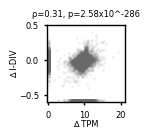

In [ ]:
outputpath_raw = f'figs_limma_equivalence/SMTSD/416/' 
logfc_df = div_limma[['logFC','adj.P.Val']].add_suffix('_div').join(tpm_limma[['logFC','adj.P.Val']].add_suffix('_tpm'))


fig, ax = plt.subplots(figsize=(1,1))
sns.scatterplot(data = logfc_df, x = 'logFC' + '_tpm', y='logFC' + '_div', edgecolor=None, color='dimgrey', alpha=0.1, s=3,ax=ax)
r, p = st.spearmanr(logfc_df['logFC' + '_tpm'], logfc_df['logFC' + '_div'])
ax.set_title(', '.join([f'ρ={r:.2f}' ,'p=' + format_small_number(p)]))
ax.tick_params(length=2.5) 
ax.set_yticklabels(ax.get_yticklabels(),x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel = '∆ TPM', ylabel = '∆ I-DIV')
fig.savefig(outputpath_raw + f'Deltas.n_{len(filt_genes)}.scatter.png', format='png', dpi=300, bbox_inches='tight')

sns.rugplot(data = logfc_df, x = 'logFC' + '_tpm', y='logFC' + '_div', color='dimgrey', alpha = 0.05, height=.03, lw=0.2)
fig.savefig(outputpath_raw + f'Deltas.n_{len(filt_genes)}_rug.scatter.png', format='png', dpi=300, bbox_inches='tight')
s = f'''
I used spermanr test
r={r}, p={p}
'''

with open(outputpath_raw + 'Deltas.about.txt', 'w') as f:
    f.write(s)
    f.close()


In [ ]:
idx_pair=416
pair_outputpath = f'tables_limma_equivalence/SMTSD_{idx_pair}/'

# pair_outputpath = f'figs_limma_equivalence/SMTSD/' + str(idx_pair) + '/'
enrichr = pd.concat([pd.read_csv(pair_outputpath + 'enrichr.cutoff_minlogFC0.05_pval0.05.div.csv.gz', index_col='Unnamed: 0').assign(metric='I-DIV'), pd.read_csv(pair_outputpath + 'enrichr.cutoff_minlogFC1_pval0.001.tpm.csv.gz', index_col='Unnamed: 0').assign(metric='TPM')])
enrichr = enrichr.loc[(enrichr['Adjusted P-value'] <= 0.05) & (enrichr['nGenesTerm'] > 5) ]
enrichr.to_csv(source_data_path + 'S3.csv.gz', compression='gzip', index=True)

In [8]:
enrichr

,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes,-log10(Adjusted P-value),-log10(P-value),QuerynGenes,BGnGenes,nGenesTerm,trend,metric
0,GO_Biological_Process_2025,Cilium Movement (GO:0003341),1.853848e-06,7.197379e-03,0,0,5.106614,67.398352,SPAG17;CCDC39;DNAH11;DNAH2;SPAG6;DNAAF1;DNAH5;...,2.142826,5.731926,1853,13328,18,Brain - Cortex up,I-DIV
1,GO_Biological_Process_2025,Inflammatory Response (GO:0006954),3.611329e-06,7.197379e-03,0,0,2.432194,30.478874,CXCL8;TRAF3IP2;PTGER3;ITGB2;LOXL3;ADM;TREM2;AD...,2.142826,5.442333,1853,13328,43,Brain - Cortex up,I-DIV
2,GO_Biological_Process_2025,Long-Chain Fatty Acid Catabolic Process (GO:00...,7.171389e-06,9.528386e-03,0,0,inf,inf,GLYATL2;ACADL;CYP4F2;ADTRP;AIG1;CYP4F12,2.020981,5.144397,1853,13328,6,Brain - Cortex up,I-DIV
3,GO_Biological_Process_2025,Phospholipase C-activating G Protein-Coupled R...,1.846460e-05,1.839997e-02,0,0,3.671577,40.018920,P2RY12;ACTN2;PLEK;PTGER3;AZU1;HTR2A;ESR1;RASGR...,1.735183,4.733660,1853,13328,20,Brain - Cortex up,I-DIV
4,GO_Biological_Process_2025,Cilium-Dependent Cell Motility (GO:0060285),2.679437e-05,2.136047e-02,0,0,6.226507,65.548428,DNAH11;DNAH2;DNAH5;DNAH6;TEKT1;DNAH14;TEKT2;RF...,1.670389,4.571956,1853,13328,12,Brain - Cortex up,I-DIV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5945,Reactome_Pathways_2024,Activation of the TFAP2 (AP-2) Family of Trans...,1.530997e-03,4.939593e-02,0,0,17.473128,113.257956,TFAP2A;TFAP2B;CREBBP;CITED2;EP300;YEATS4,1.306309,2.815026,3411,13328,6,Brain - Cerebellum up,TPM
5946,Reactome_Pathways_2024,Post-transcriptional Silencing by Small RNAs,1.530997e-03,4.939593e-02,0,0,17.473128,113.257956,TNRC6C;AGO3;AGO4;AGO2;TNRC6A;TNRC6B,1.306309,2.815026,3411,13328,6,Brain - Cerebellum up,TPM
5947,Reactome_Pathways_2024,Regulation of Expression and Function of Type ...,1.556594e-03,4.939593e-02,0,0,3.790200,24.504610,JUP;ADAM19;TNRC6C;ILF3;AGO3;AGO4;SP1;ZC3H12A;A...,1.306309,2.807825,3411,13328,13,Brain - Cerebellum up,TPM
5948,Reactome_Pathways_2024,Regulation of Homotypic Cell-Cell Adhesion,1.556594e-03,4.939593e-02,0,0,3.790200,24.504610,JUP;ADAM19;TNRC6C;ILF3;AGO3;AGO4;SP1;ZC3H12A;A...,1.306309,2.807825,3411,13328,13,Brain - Cerebellum up,TPM


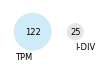

In [ ]:
t = t1 + ' up'
venn_s = enrichr.loc[enrichr.trend == t].metric.value_counts()
venn_s.loc['intersect'] = len(np.intersect1d(enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='TPM')].Term.unique(), enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='I-DIV')].Term.unique()))
venn_s.name = t1
fig, ax = plt.subplots(figsize=(1,1))
v = venn2(subsets=venn_s.astype(int), set_labels=['TPM', 'I-DIV'], set_colors=('silver', 'skyblue'),ax=ax)
for text in v.set_labels:
    if text:
        text.set_fontsize(6)
for text in v.subset_labels:
    if text:
        text.set_fontsize(6)

fig.savefig(f'figs_limma_equivalence/SMTSD/{idx_pair}/' + f'TermCount.{t.replace(' ', '_')}.png', format='png', dpi=300, bbox_inches='tight')

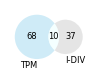

In [ ]:
t = t2 + ' up'
venn_s = enrichr.loc[enrichr.trend == t].metric.value_counts()
venn_s.loc['intersect'] = len(np.intersect1d(enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='TPM')].Term.unique(), enrichr.loc[(enrichr.trend == t) & (enrichr.metric=='I-DIV')].Term.unique()))
venn_s.name = t2
fig, ax = plt.subplots(figsize=(1,1))
v = venn2(subsets=venn_s.astype(int), set_labels=['TPM', 'I-DIV'], set_colors=('silver', 'skyblue'),ax=ax)
for text in v.set_labels:
    if text:
        text.set_fontsize(6)
for text in v.subset_labels:
    if text:
        text.set_fontsize(6)
fig.savefig(f'figs_limma_equivalence/SMTSD/{idx_pair}/' + f'TermCount.{t.replace(' ', '_')}.png', format='png', dpi=300, bbox_inches='tight')

In [ ]:


"""
Abbreviate GO (Gene Ontology) Biological Process term labels for plotting,
e.g. shortening ytick labels on Enrichr-style dot plots.

Usage:
    from abbreviate_go_terms import abbreviate_go_terms

    labels = [
        "Regulation of DNA-templated Transcription (n=725)",
        "Positive Regulation of Cell Projection Organization (n=44)",
    ]
    short_labels = [abbreviate_go_terms(l) for l in labels]

    # Or directly on a matplotlib axis:
    ax.set_yticklabels([abbreviate_go_terms(t.get_text()) for t in ax.get_yticklabels()])
"""

import re

# Ordered list of (pattern, replacement). Order matters: longer/more specific
# phrases are matched before shorter general words so multi-word terms like
# "G Protein-Coupled Receptor" become "GPCR" before "Receptor" or "Protein"
# get touched individually.
_ABBREVIATIONS = [
    # Multi-word standard abbreviations (match first)
    (r"\bG Protein-Coupled Receptor\b", "GPCR"),
    (r"\bRNA Polymerase II\b", "RNA Pol II"),
    (r"\bDNA-templated\b", "DNA-templated"),  # kept as-is, placeholder for clarity

    # Common GO-term words -> abbreviations
    (r"\bRegulation\b", "Reg."),
    (r"\bPositive Regulation\b", "Pos. Reg."),
    (r"\bNegative Regulation\b", "Neg. Reg."),
    (r"\bPositive\b", "Pos."),
    (r"\bNegative\b", "Neg."),
    (r"\bOrganization\b", "Org."),
    (r"\bDevelopment\b", "Dev."),
    (r"\bDifferentiation\b", "Diff."),
    (r"\bTranscription\b", "Transcr."),
    (r"\bTranslation\b", "Transl."),
    (r"\bTransduction\b", "Transd."),
    (r"\bLocalization\b", "Localiz."),
    (r"\bBiosynthetic\b", "Biosynth."),
    (r"\bMetabolic\b", "Metab."),
    (r"\bCatabolic\b", "Catab."),
    (r"\bMacromolecule\b", "Macromol."),
    (r"\bMitochondrial\b", "Mito."),
    (r"\bMitochondrion\b", "Mito."),
    (r"\bElectron\b", "e-"),
]

# Apply "Positive Regulation" / "Negative Regulation" before the standalone
# "Regulation" rule so they aren't double-abbreviated (e.g. "Pos. Reg. Reg.").
_ABBREVIATIONS.sort(key=lambda pr: -len(pr[0]))


def abbreviate_go_terms(label: str) -> str:
    """
    Abbreviate a single GO Biological Process label using a fixed set of
    common word substitutions. The trailing "(n=NN)" count, if present, is
    preserved as-is.

    Parameters
    ----------
    label : str
        Original GO term label, e.g. "Regulation of DNA-templated Transcription (n=725)"

    Returns
    -------
    str
        Abbreviated label, e.g. "Reg. of DNA-templated Transcr. (n=725)"
    """
    out = label
    for pattern, repl in _ABBREVIATIONS:
        out = re.sub(pattern, repl, out, flags=re.IGNORECASE)
    return out


In [11]:
t2 = 'Brain - Cortex' ; t1 = 'Brain - Cerebellum'
cplt = {t1: 'Teal', t2: 'Coral'}

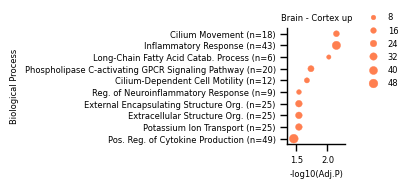

In [ ]:

t = t2 + ' up'
trend_df = enrichr[(enrichr['Gene_set'] == 'GO_Biological_Process_2025') & (enrichr['trend'] == t) & (enrichr['metric'] == 'I-DIV')].head(10)

fig, ax = plt.subplots(figsize=(0.75,len(trend_df)/6.67 ))
sns.scatterplot(data = trend_df, x = '-log10(Adjusted P-value)', y= 'Term', color = cplt[' '.join(t.split(' ')[:-1])], edgecolor=None, size='nGenesTerm', sizes=(10,40), zorder = 6)
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)

yaxis_labels = [y.get_text() for y in ax.get_yticklabels()]
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]

labels= []
for i, label in enumerate(labels_raw):
    
    if yaxis_labels[i] in trend_df.Term.unique():
        labels += [label + f' (n={list(trend_df.loc[trend_df.Term == yaxis_labels[i], "nGenesTerm"])[0]})']
    else:
        labels += [label]

ax.set_yticklabels(labels)
ax.set_yticklabels([abbreviate_go_terms(l) for l in labels])
ax.set(ylabel='Biological Process', xlabel = '-log10(Adj.P)', title = t)
ax.set_xlim(ax.get_xlim()[0] * 0.95,ax.get_xlim()[1] * 1.05)

sns.despine()

fig.savefig(f'figs_limma_equivalence/SMTSD/416/div/{t}.cutoff_minlogFC0.05_pval0.05.abb.png', format='png', dpi=300, bbox_inches='tight')

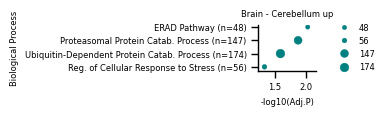

In [ ]:
t = t1 + ' up'
trend_df = enrichr[(enrichr['Gene_set'] == 'GO_Biological_Process_2025') & (enrichr['trend'] == t) & (enrichr['metric'] == 'I-DIV')].head(10)

fig, ax = plt.subplots(figsize=(0.75,len(trend_df)/6.67 ))
sns.scatterplot(data = trend_df, x = '-log10(Adjusted P-value)', y= 'Term', color = cplt[' '.join(t.split(' ')[:-1])], edgecolor=None, size='nGenesTerm', sizes=(10,40), zorder = 6)
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)

yaxis_labels = [y.get_text() for y in ax.get_yticklabels()]
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]

labels= []
for i, label in enumerate(labels_raw):
    
    if yaxis_labels[i] in trend_df.Term.unique():
        labels += [label + f' (n={list(trend_df.loc[trend_df.Term == yaxis_labels[i], "nGenesTerm"])[0]})']
    else:
        labels += [label]

ax.set_yticklabels(labels)
ax.set_yticklabels([abbreviate_go_terms(l) for l in labels])
ax.set(ylabel='Biological Process', xlabel = '-log10(Adj.P)', title = t)
ax.set_xlim(ax.get_xlim()[0] * 0.95,ax.get_xlim()[1] * 1.05)
ax.set_ylim(ax.set_ylim()[0] * 1.05,ax.set_ylim()[1] * 1.15)

sns.despine()
fig.savefig(f'figs_limma_equivalence/SMTSD/416/div/{t}.cutoff_minlogFC0.05_pval0.05.abb.png', format='png', dpi=300, bbox_inches='tight')

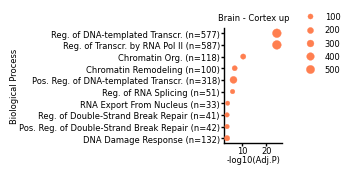

In [ ]:
trend_df = enrichr[(enrichr['Gene_set'] == 'GO_Biological_Process_2025') & (enrichr['trend'] == t) & (enrichr['metric'] == 'TPM')].head(10)
t = t2 + ' up'
fig, ax = plt.subplots(figsize=(0.75,len(trend_df)/6.67 ))
sns.scatterplot(data = trend_df, x = '-log10(Adjusted P-value)', y= 'Term', color = cplt[' '.join(t.split(' ')[:-1])], edgecolor=None, size='nGenesTerm', sizes=(10,40), zorder = 6, legend=True)
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)
yaxis_labels = [y.get_text() for y in ax.get_yticklabels()]
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]

labels= []
for i, label in enumerate(labels_raw):
    
    if yaxis_labels[i] in trend_df.Term.unique():
        labels += [label + f' (n={list(trend_df.loc[trend_df.Term == yaxis_labels[i], "nGenesTerm"])[0]})']
    else:
        labels += [label]

ax.set_yticklabels(labels)
ax.set_yticklabels(abbreviate_go_terms(l) for l in labels)
ax.set(ylabel='Biological Process', xlabel = '-log10(Adj.P)', title = t)
ax.set_xlim(ax.get_xlim()[0] * 0.95,ax.get_xlim()[1] * 1.05)

ax.tick_params(length=2.5) 
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)   

sns.despine()

fig.savefig(f'figs_limma_equivalence/SMTSD/416/tpm/{t}.cutoff_minlogFC1_pval0.001.abb.png', format='png', dpi=300, bbox_inches='tight')


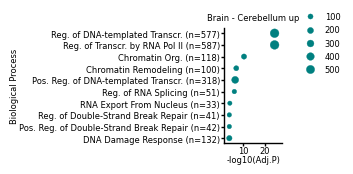

In [ ]:
label_abbrev = {
    "Potassium Ion Transport (n=16)": "Potassium Ion Transport (n=16)",
    "Potassium Ion Transmembrane Transport (n=16)": "Potassium Ion Transmembrane Transport (n=16)",
    "Adenylate Cyclase-Modulating G Protein-Coupled Receptor Signaling Pathway (n=18)": "Adenylate Cyclase-Modulating GPCR Signaling Pathway (n=18)",
    "Chemical Synaptic Transmission (n=24)": "Chemical Synaptic Transmission (n=24)",
    "Regulation of Filopodium Assembly (n=9)": "Reg. of Filopodium Assembly (n=9)",
    "Nervous System Development (n=38)": "Nervous System Dev. (n=38)",
    "Embryonic Digestive Tract Development (n=6)": "Embryonic Digestive Tract Dev. (n=6)",
    "cAMP-mediated Signaling (n=7)": "cAMP-mediated Signaling (n=7)",
    "Neuron Differentiation (n=16)": "Neuron Differentiation (n=16)",
}

t = t1 + ' up'
trend_df = enrichr[(enrichr['Gene_set'] == 'GO_Biological_Process_2025') & (enrichr['trend'] == t) & (enrichr['metric'] == 'TPM')].head(10)

fig, ax = plt.subplots(figsize=(0.75,len(trend_df)/6.67 ))
sns.scatterplot(data = trend_df, x = '-log10(Adjusted P-value)', y= 'Term', color = cplt[' '.join(t.split(' ')[:-1])], edgecolor=None, size='nGenesTerm', sizes=(10,40), zorder = 6, legend=True)
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)
yaxis_labels = [y.get_text() for y in ax.get_yticklabels()]
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]

labels= []
for i, label in enumerate(labels_raw):
    
    if yaxis_labels[i] in trend_df.Term.unique():
        labels += [label + f' (n={list(trend_df.loc[trend_df.Term == yaxis_labels[i], "nGenesTerm"])[0]})']
    else:
        labels += [label]

ax.set_yticklabels(labels)
ax.set_yticklabels([abbreviate_go_terms(l) for l in labels])
ax.set(ylabel='Biological Process', xlabel = '-log10(Adj.P)', title = t)
ax.set_xlim(ax.get_xlim()[0] * 0.5,ax.get_xlim()[1] * 1.1)

ax.tick_params(length=2.5) 
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)   

sns.despine()
fig.savefig(f'figs_limma_equivalence/SMTSD/416/tpm/{t}.cutoff_minlogFC1_pval0.001.abb.png', format='png', dpi=300, bbox_inches='tight')